# H2O AutoML — Open-Meteo: Hà Nội, Đà Nẵng, TP.HCM
**Bản riêng, không thay bản đã gửi leader.** Chạy các ô từ trên xuống hoặc Chạy tất cả.

Mục tiêu: dùng dữ liệu hoàn tất của ngày t và lịch sử trước đó để dự đoán **AQI trung bình ngày t+1**.
Nguồn là đầu ra mô hình khí quyển CAMS do Open-Meteo cung cấp, không phải số đo trực tiếp của trạm.
CSV lịch sử: 01/01/2023–04/10/2026. CSV dự báo 05–09/10/2026 lưu riêng, không dùng train/test.
Giờ Việt Nam. Mỗi tọa độ đại diện một ô lưới, không đại diện mọi quận trong thành phố.

Mỗi lần chạy tạo một thư mục kết quả mới; CSV gốc chỉ đọc, không ghi đè. Code và log từng ô tự lưu Drive.
H2O thử GLM, GBM, DRF, XRT, XGBoost, DeepLearning và StackedEnsemble.
XRT thuộc DRF; StackedEnsemble học cách kết hợp các mô hình đơn.

## 0. Kết nối Drive, tạo bản riêng và tự lưu từng ô code

In [2]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib, json, platform, sys

SOURCE_DIR = Path('/content/drive/MyDrive/Bigdata_H20')
assert (SOURCE_DIR / 'Data_OpenMeteo.zip').is_file(), f'Không thấy ZIP trong {SOURCE_DIR}. Kiểm tra đường dẫn.'
PROJECT = SOURCE_DIR / 'OpenMeteo_H2O_3_ThanhPho'
PROJECT.mkdir(exist_ok=True)
RUN_ID = datetime.now(ZoneInfo('Asia/Ho_Chi_Minh')).strftime('%Y%m%d_%H%M%S_%f')
RUN = PROJECT / 'runs' / RUN_ID
for name in ['code', 'logs', 'reports', 'figures', 'processed', 'features', 'splits', 'metrics', 'models', 'predictions', 'notebooks']:
    (RUN / name).mkdir(parents=True, exist_ok=True)
def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

ip = get_ipython()
# Gỡ hook của lần chạy trước để một ô chỉ ghi vào đúng lần chạy hiện tại.
for event, func in globals().get('_audit_hooks', []):
    ip.events.unregister(event, func)
_audit_counter = 0
_audit_current = None
def _audit_before(info):
    global _audit_counter, _audit_current
    _audit_counter += 1
    source = info.raw_cell
    digest = hashlib.sha256(source.encode()).hexdigest()
    path = RUN / 'code' / f'{_audit_counter:02d}_{digest[:10]}.py'
    path.write_text(source, encoding='utf-8')
    _audit_current = {'cell': _audit_counter, 'file': str(path), 'sha256': digest, 'started': datetime.now().isoformat()}
def _audit_after(result):
    if _audit_current is None:
        return
    entry = dict(_audit_current)
    entry['finished'] = datetime.now().isoformat()
    error = result.error_before_exec or result.error_in_exec
    entry['status'] = 'error' if error else 'ok'
    entry['error'] = str(error) if error else None
    with (RUN / 'logs' / 'cells.jsonl').open('a', encoding='utf-8') as f:
        f.write(json.dumps(entry, ensure_ascii=False) + '\n')

_audit_hooks = [('pre_run_cell', _audit_before), ('post_run_cell', _audit_after)]
for event, func in _audit_hooks:
    ip.events.register(event, func)
# Lưu cả ô thiết lập đang chạy sau khi đã kết nối Drive.
setup_source = ip.history_manager.input_hist_raw[-1]
(RUN / 'code' / '00_setup.py').write_text(setup_source, encoding='utf-8')
save_json({'run_id': RUN_ID, 'source_dir': str(SOURCE_DIR), 'target': 'next_day_mean_us_aqi',
           'source': 'CAMS model output via Open-Meteo', 'timezone': 'Asia/Ho_Chi_Minh',
           'python': sys.version, 'created': datetime.now().isoformat()}, RUN / 'reports' / 'config.json')
print('Lưu mọi đầu ra tại:', RUN)

Mounted at /content/drive
Lưu mọi đầu ra tại: /content/drive/MyDrive/Bigdata_H20/OpenMeteo_H2O_3_ThanhPho/runs/20261005_233342_901346


## 1. Cài thư viện và đọc CSV nguyên bản từ ZIP (không sửa CSV gốc)

In [3]:
import subprocess, io, zipfile, shutil
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'h2o==3.46.0.8'])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h2o
from h2o.automl import H2OAutoML, get_leaderboard
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True, 'grid.alpha': 0.2})

CITY_MAP = {0: 'Ha Noi', 1: 'Da Nang', 2: 'TP.HCM'}
HISTORY_NAME = 'air_quality_3_cities_20230101_20261004.csv'
FORECAST_NAME = 'forecast_3_cities_20261005_20261009.csv'
raw_dir = PROJECT / 'raw'
raw_dir.mkdir(exist_ok=True)
manifest = []
def read_source_csv(payload):
    metadata = pd.read_csv(io.BytesIO(payload), nrows=3)
    table = pd.read_csv(io.BytesIO(payload), skiprows=5)
    assert set(metadata.location_id) == {0, 1, 2}
    assert (metadata.utc_offset_seconds == 25200).all(), 'Nguồn không dùng giờ Việt Nam.'
    assert set(table.location_id) == {0, 1, 2}
    return metadata, table

with zipfile.ZipFile(SOURCE_DIR / 'Data_OpenMeteo.zip') as z:
    for filename in [HISTORY_NAME, FORECAST_NAME]:
        members = [n for n in z.namelist() if Path(n).name == filename]
        assert len(members) == 1, f'Cần đúng một file {filename}, tìm được {members}'
        payload = z.read(members[0])
        digest = hashlib.sha256(payload).hexdigest()
        target = raw_dir / filename
        if target.exists():
            assert hashlib.sha256(target.read_bytes()).hexdigest() == digest, 'CSV raw đã khác ZIP; dừng để kiểm tra.'
        else:
            target.write_bytes(payload)  # Sao chép nguyên byte; không ghi lại bằng pandas.
        manifest.append({'file': filename, 'sha256': digest, 'bytes': len(payload)})
history_meta, raw_history = read_source_csv((raw_dir / HISTORY_NAME).read_bytes())
forecast_meta, raw_forecast = read_source_csv((raw_dir / FORECAST_NAME).read_bytes())
save_json(manifest, RUN / 'reports' / 'raw_manifest.json')
save_json({'pandas': pd.__version__, 'numpy': np.__version__, 'h2o': h2o.__version__}, RUN / 'reports' / 'versions.json')
print('Lịch sử:', raw_history.shape, '| Dự báo riêng:', raw_forecast.shape)
display(history_meta, raw_history.head(), raw_forecast.head())

Lịch sử: (98856, 9) | Dự báo riêng: (360, 9)


,location_id,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,0,21.000000,105.899994,19.0,25200,Asia/Ho_Chi_Minh,GMT+7
1,1,16.099998,108.200010,6.0,25200,Asia/Ho_Chi_Minh,GMT+7
2,2,10.800003,106.600006,6.0,25200,Asia/Ho_Chi_Minh,GMT+7


,location_id,time,pm10 (μg/m³),pm2_5 (μg/m³),carbon_monoxide (μg/m³),nitrogen_dioxide (μg/m³),sulphur_dioxide (μg/m³),ozone (μg/m³),us_aqi (USAQI)
0,0,2023-01-01T00:00,74.7,52.4,678.0,8.8,15.4,58.0,146
1,0,2023-01-01T01:00,64.3,45.1,622.0,6.5,15.2,57.0,142
2,0,2023-01-01T02:00,57.6,40.4,603.0,5.7,14.9,56.0,138
3,0,2023-01-01T03:00,54.7,38.3,599.0,5.8,14.8,55.0,135
4,0,2023-01-01T04:00,54.0,37.8,602.0,6.4,14.6,52.0,133


,location_id,time,pm10 (μg/m³),pm2_5 (μg/m³),carbon_monoxide (μg/m³),nitrogen_dioxide (μg/m³),sulphur_dioxide (μg/m³),ozone (μg/m³),us_aqi (USAQI)
0,0,2026-10-05T00:00,11.8,11.8,478.0,8.6,8.3,67.0,77
1,0,2026-10-05T01:00,11.7,11.6,413.0,8.3,6.9,66.0,76
2,0,2026-10-05T02:00,11.7,11.7,367.0,8.0,6.1,63.0,74
3,0,2026-10-05T03:00,11.2,11.2,336.0,7.9,5.6,60.0,73
4,0,2026-10-05T04:00,11.1,11.1,330.0,8.4,5.5,56.0,71


## 2. Thống kê và biểu đồ TRƯỚC tiền xử lý

,location_id,pm10 (μg/m³),pm2_5 (μg/m³),carbon_monoxide (μg/m³),nitrogen_dioxide (μg/m³),sulphur_dioxide (μg/m³),ozone (μg/m³),us_aqi (USAQI)
count,98856.000000,98856.000000,98856.000000,98856.000000,98856.000000,98856.000000,98856.000000,98856.000000
mean,1.000000,38.712863,30.565650,574.939336,21.530971,18.527102,81.055940,98.212511
std,0.816501,25.944995,22.235817,434.833885,19.024862,14.303595,56.220586,39.728224
min,0.000000,0.800000,0.600000,33.000000,0.000000,0.000000,0.000000,25.000000
25%,0.000000,21.700000,16.200000,316.000000,6.700000,6.500000,40.000000,68.000000
50%,1.000000,31.900000,24.300000,456.000000,15.500000,16.400000,71.000000,86.000000
75%,2.000000,47.100000,37.400000,678.000000,31.500000,26.700000,111.000000,119.250000
max,2.000000,291.500000,232.800000,5494.000000,162.500000,104.600000,418.000000,284.000000


,missing
location_id,0
time,0
pm10 (μg/m³),0
pm2_5 (μg/m³),0
carbon_monoxide (μg/m³),0
nitrogen_dioxide (μg/m³),0
sulphur_dioxide (μg/m³),0
ozone (μg/m³),0
us_aqi (USAQI),0


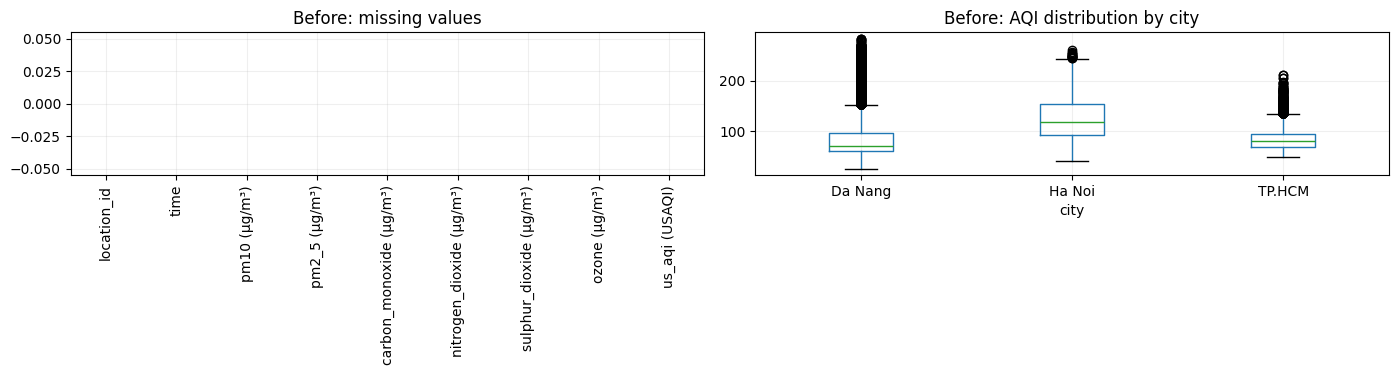

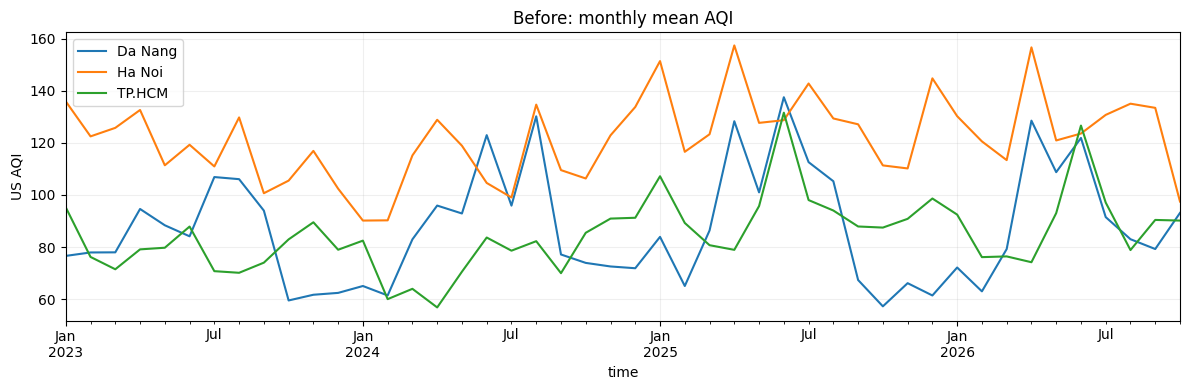

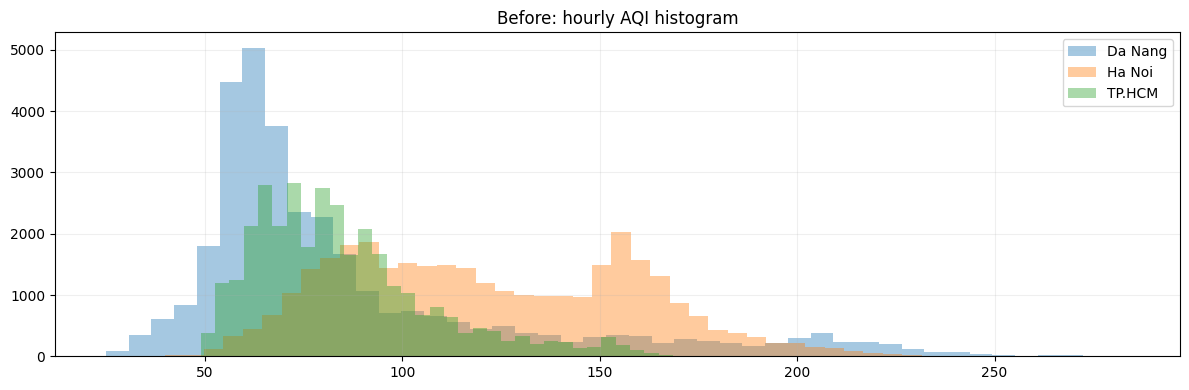

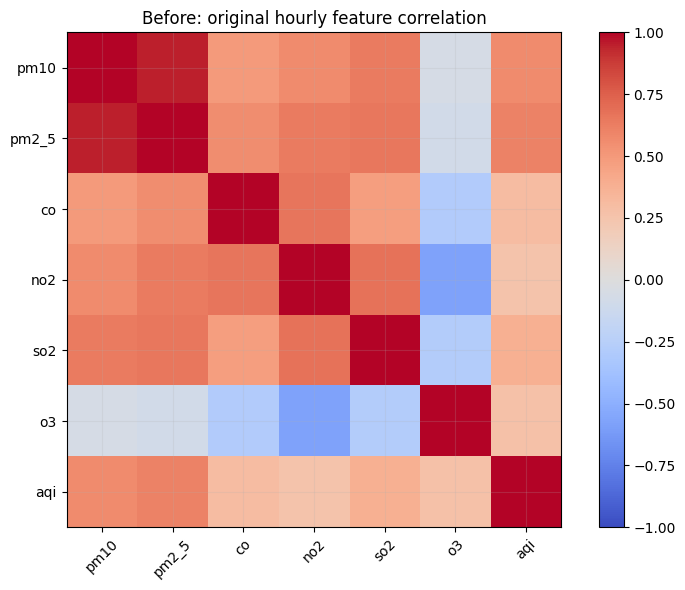

SAVED: before_correlation.csv and 02_before_correlation.png /content/drive/MyDrive/Bigdata_H20/OpenMeteo_H2O_3_ThanhPho/runs/20261005_233342_901346


In [17]:
def save_figure(name):
    plt.tight_layout()
    plt.savefig(RUN / 'figures' / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

raw_history.describe(include='all').to_csv(RUN / 'reports' / 'before_describe.csv')
missing_before = raw_history.isna().sum().rename('missing')
missing_before.to_csv(RUN / 'reports' / 'before_missing.csv')
display(raw_history.describe(), missing_before.to_frame())
preview = raw_history.assign(time=pd.to_datetime(raw_history.time), city=raw_history.location_id.map(CITY_MAP))
aqi_col = 'us_aqi (USAQI)'
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
missing_before.plot.bar(ax=axes[0], title='Before: missing values')
preview.boxplot(column=aqi_col, by='city', ax=axes[1])
axes[1].set_title('Before: AQI distribution by city')
fig.suptitle('')
save_figure('02_before_missing_boxplot.png')
for city, group in preview.groupby('city'):
    group.set_index('time')[aqi_col].resample('MS').mean().plot(label=city)
plt.title('Before: monthly mean AQI'); plt.ylabel('US AQI'); plt.legend()
save_figure('02_before_monthly_aqi.png')
for city, group in preview.groupby('city'):
    plt.hist(group[aqi_col].dropna(), bins=45, alpha=0.4, label=city)
plt.title('Before: hourly AQI histogram'); plt.legend()
save_figure('02_before_aqi_histogram.png')
# Pearson correlation of original hourly values (no cleaning or aggregation).
raw_corr_columns = ['pm10 (μg/m³)', 'pm2_5 (μg/m³)', 'carbon_monoxide (μg/m³)', 'nitrogen_dioxide (μg/m³)', 'sulphur_dioxide (μg/m³)', 'ozone (μg/m³)', 'us_aqi (USAQI)']
raw_corr_labels = ['pm10', 'pm2_5', 'co', 'no2', 'so2', 'o3', 'aqi']
before_corr = raw_history[raw_corr_columns].corr(method='pearson')
before_corr.index = raw_corr_labels
before_corr.columns = raw_corr_labels
assert before_corr.shape == (7, 7)
assert np.allclose(before_corr, before_corr.T, equal_nan=True)
before_corr.to_csv(RUN / 'reports' / 'before_correlation.csv')
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(before_corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(7), raw_corr_labels, rotation=45)
ax.set_yticks(range(7), raw_corr_labels)
fig.colorbar(im, ax=ax)
ax.set_title('Before: original hourly feature correlation')
save_figure('02_before_correlation.png')
print('SAVED: before_correlation.csv and 02_before_correlation.png', RUN)


## 3. Kiểm tra và làm sạch dữ liệu lịch sử
Chuyển kiểu, kiểm tra mốc giờ, xử lý giá trị âm/không hữu hạn thành thiếu, loại bản ghi trùng hoàn toàn.
Không tự loại các đợt ô nhiễm cao; không nội suy từ tương lai; không sửa file raw.
Nếu có hai bản ghi khác nhau cùng thành phố/giờ, dừng để kiểm tra thay vì chọn tùy ý.

In [5]:
RENAME = {'pm10 (μg/m³)': 'pm10', 'pm2_5 (μg/m³)': 'pm2_5',
          'carbon_monoxide (μg/m³)': 'co', 'nitrogen_dioxide (μg/m³)': 'no2',
          'sulphur_dioxide (μg/m³)': 'so2', 'ozone (μg/m³)': 'o3', 'us_aqi (USAQI)': 'aqi'}
VALUES = list(RENAME.values())
def clean_hourly(raw):
    data = raw.rename(columns=RENAME).copy()
    assert all(c in data.columns for c in VALUES)
    data['time'] = pd.to_datetime(data['time'], errors='raise')
    data['city'] = data.location_id.map(CITY_MAP)
    assert data.city.notna().all()
    for col in VALUES:
        data[col] = pd.to_numeric(data[col], errors='coerce')
        data.loc[~np.isfinite(data[col]) | (data[col] < 0), col] = np.nan
    data = data.drop_duplicates()
    assert not data.duplicated(['city', 'time']).any(), 'Trùng mốc giờ nhưng khác giá trị.'
    assert (data.time.dt.minute == 0).all()
    data = data.sort_values(['city', 'time']).reset_index(drop=True)
    return data

hourly = clean_hourly(raw_history)
assert hourly.time.min() == pd.Timestamp('2023-01-01')
assert hourly.time.max() == pd.Timestamp('2026-10-04 23:00')
hourly.to_csv(RUN / 'processed' / 'hourly_clean.csv', index=False)
quality = []
for city, group in hourly.groupby('city'):
    expected = pd.date_range(group.time.min(), group.time.max(), freq='h')
    quality.append({'city': city, 'rows': len(group), 'missing_hours': len(expected.difference(group.time)),
                    'missing_values': int(group[VALUES].isna().sum().sum()),
                    'start': group.time.min(), 'end': group.time.max()})
quality = pd.DataFrame(quality)
quality.to_csv(RUN / 'reports' / 'hourly_quality.csv', index=False)
display(quality)

,city,rows,missing_hours,missing_values,start,end
0,Da Nang,32952,0,0,2023-01-01,2026-10-04 23:00:00
1,Ha Noi,32952,0,0,2023-01-01,2026-10-04 23:00:00
2,TP.HCM,32952,0,0,2023-01-01,2026-10-04 23:00:00


## 4. Tổng hợp theo ngày và biểu đồ SAU tiền xử lý

pm10                                              pm2_5             \
        count       mean        std        min         max count       mean   
city                                                                          
Da Nang  1373  26.962303  12.175934   5.445833  108.858333  1373  19.256403   
Ha Noi   1373  55.856185  24.859954  11.041667  174.970833  1373  45.811772   
TP.HCM   1373  33.320102  11.905939  10.687500   79.529167  1373  26.628775   

                                          ...    o3                         \
               std       min         max  ... count        mean        std   
city                                      ...                                
Da Nang   8.786243  4.629167   79.312500  ...  1373  110.086338  29.848012   
Ha Noi   20.917745  7.745833  134.279167  ...  1373   77.214979  27.019800   
TP.HCM   10.670699  8.900000   71.787500  ...  1373   55.866503  18.043570   

                                 aqi                                    \
               min         max count        mean        std        min   
city                                                                     
Da Nang  34.666667  216.416667  1373   87.470017  33.030883  29.583333   
Ha Noi   19.083333  169.625000  1373  122.294034  33.706574  48.125000   
TP.HCM   16.083333  119.875000  1373   84.873483  21.617466  50.125000   

                     
                max  
city                 
Da Nang  204.666667  
Ha Noi   212.500000  
TP.HCM   163.083333  

[3 rows x 35 columns]

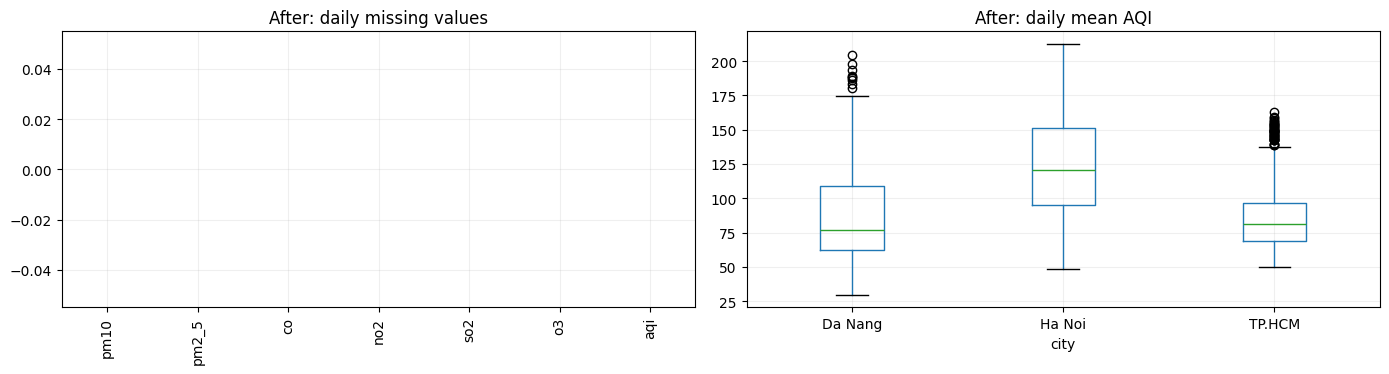

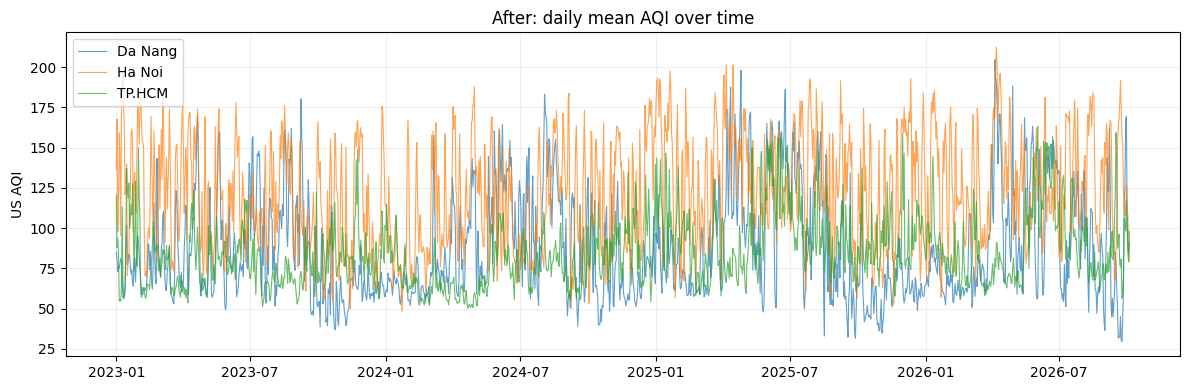

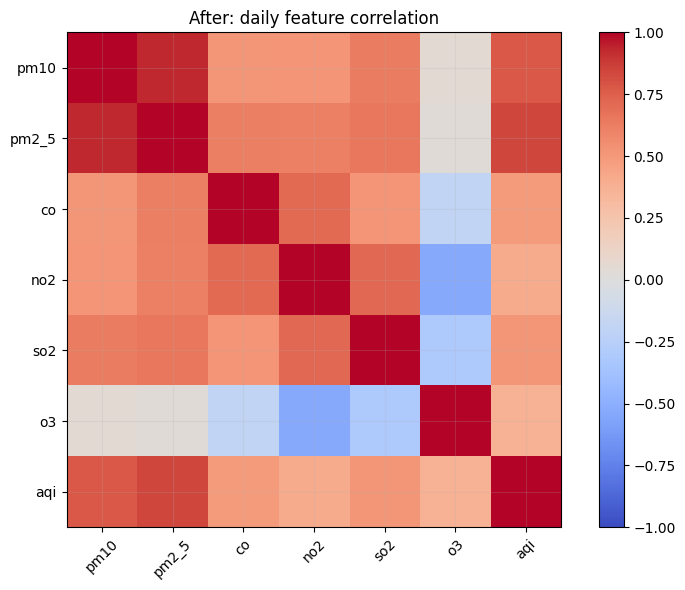

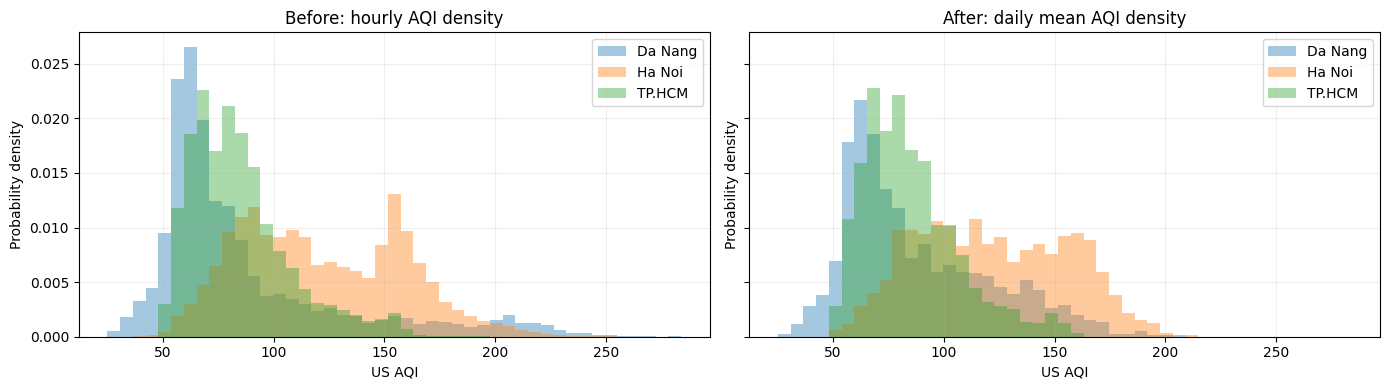

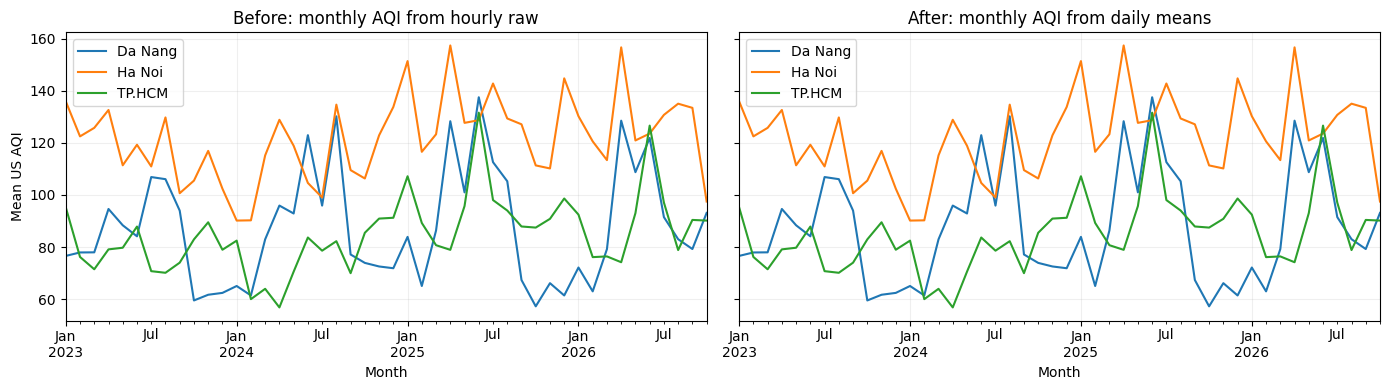

,stage,rows,missing_original_cells,missing_numeric_cells,negative_cells,infinite_cells,duplicate_keys
0,before_hourly,98856,0,0,0,0,0
1,after_hourly,98856,0,0,0,0,0
2,after_daily,4119,0,0,0,0,0


PAIRED EDA SAVED: histogram, monthly trend, numeric statistics, quality audit, correlation CSV.


In [19]:
def to_daily(data):
    temp = data.assign(date=data.time.dt.normalize())
    grouped = temp.groupby(['city', 'date'])
    means = grouped[VALUES].mean()
    counts = grouped[VALUES].count().add_suffix('_count')
    daily_table = means.join(counts)
    daily_table['hour_count'] = grouped.size()
    daily_table['aqi_max'] = grouped.aqi.max()
    daily_table['pm2_5_std'] = grouped.pm2_5.std()
    # Ngày thiếu giờ/thiếu AQI không được dùng làm nhãn; giữ dòng để lag không nhảy qua ngày thiếu.
    daily_table.loc[(daily_table.hour_count != 24) | (daily_table.aqi_count != 24), 'aqi'] = np.nan
    result = []
    for city, group in daily_table.reset_index().groupby('city'):
        group = group.set_index('date').reindex(pd.date_range(group.date.min(), group.date.max(), freq='D'))
        group.index.name = 'date'
        group['city'] = city
        result.append(group.reset_index())
    return pd.concat(result, ignore_index=True).sort_values(['city', 'date']).reset_index(drop=True)

daily = to_daily(hourly)
daily.to_csv(RUN / 'processed' / 'daily_clean.csv', index=False)
daily.describe(include='all').to_csv(RUN / 'reports' / 'after_daily_describe.csv')
display(daily.groupby('city')[VALUES].agg(['count', 'mean', 'std', 'min', 'max']))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
daily[VALUES].isna().sum().plot.bar(ax=axes[0], title='After: daily missing values')
daily.boxplot(column='aqi', by='city', ax=axes[1]); axes[1].set_title('After: daily mean AQI')
fig.suptitle(''); save_figure('04_after_missing_boxplot.png')
for city, group in daily.groupby('city'):
    plt.plot(group.date, group.aqi, label=city, alpha=0.7, linewidth=0.8)
plt.title('After: daily mean AQI over time'); plt.ylabel('US AQI'); plt.legend()
save_figure('04_after_daily_aqi.png')
corr = daily[VALUES].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(VALUES)), VALUES, rotation=45); ax.set_yticks(range(len(VALUES)), VALUES)
fig.colorbar(im, ax=ax); ax.set_title('After: daily feature correlation')
save_figure('04_after_correlation.png')
# Paired EDA: same bins, units, time resolution and axis limits.
raw_numeric = raw_history[list(RENAME)].apply(pd.to_numeric, errors='coerce')
raw_numeric.columns = VALUES
quality_rows = []
for stage, data, keys in [('before_hourly', raw_history, ['location_id','time']), ('after_hourly', hourly, ['city','time']), ('after_daily', daily, ['city','date'])]:
    numeric = raw_numeric if stage == 'before_hourly' else data[VALUES]
    numeric = numeric.apply(pd.to_numeric, errors='coerce')
    quality_rows.append({'stage': stage, 'rows': len(data), 'missing_original_cells': int(data[list(RENAME) if stage == 'before_hourly' else VALUES].isna().sum().sum()), 'missing_numeric_cells': int(numeric.isna().sum().sum()), 'negative_cells': int((numeric < 0).sum().sum()), 'infinite_cells': int(np.isinf(numeric.to_numpy(dtype=float)).sum()), 'duplicate_keys': int(data.duplicated(keys).sum())})
quality_comparison = pd.DataFrame(quality_rows)
quality_comparison.to_csv(RUN / 'reports' / 'quality_before_after.csv', index=False)
after_corr = daily[VALUES].corr(method='pearson')
after_corr.to_csv(RUN / 'reports' / 'after_correlation.csv')
raw_numeric.describe().to_csv(RUN / 'reports' / 'before_numeric_describe.csv')
daily[VALUES].describe().to_csv(RUN / 'reports' / 'after_numeric_describe.csv')
all_aqi = pd.concat([raw_numeric.aqi, daily.aqi]).replace([np.inf, -np.inf], np.nan).dropna()
common_bins = np.linspace(all_aqi.min(), all_aqi.max(), 46)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True, sharey=True)
for ax, data, title in [(axes[0], raw_history.assign(city=raw_history.location_id.map(CITY_MAP), aqi=raw_numeric.aqi), 'Before: hourly AQI density'), (axes[1], daily, 'After: daily mean AQI density')]:
    for city, group in data.groupby('city'):
        ax.hist(group.aqi.dropna(), bins=common_bins, density=True, alpha=0.4, label=city)
    ax.set(title=title, xlabel='US AQI', ylabel='Probability density')
    ax.legend()
save_figure('04_before_after_aqi_histogram.png')
raw_monthly = raw_history.assign(city=raw_history.location_id.map(CITY_MAP), time=pd.to_datetime(raw_history.time), aqi=raw_numeric.aqi).set_index('time').groupby('city').aqi.resample('MS').mean()
# Weight daily means by hourly counts so monthly aggregation remains comparable.
daily_monthly = daily.assign(month=daily.date.dt.to_period('M').dt.to_timestamp(), weighted=daily.aqi*daily.aqi_count).groupby(['city','month']).agg(total=('weighted','sum'), count=('aqi_count','sum'))
daily_monthly['aqi'] = daily_monthly.total / daily_monthly['count']
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True, sharey=True)
for city in sorted(CITY_MAP.values()):
    raw_monthly.loc[city].plot(ax=axes[0], label=city)
    daily_monthly.loc[city].aqi.plot(ax=axes[1], label=city)
for ax, title in zip(axes, ['Before: monthly AQI from hourly raw', 'After: monthly AQI from daily means']):
    ax.set(title=title, xlabel='Month', ylabel='Mean US AQI'); ax.legend()
save_figure('04_before_after_monthly_aqi.png')
assert len(quality_comparison) == 3
assert sum(quality_comparison.duplicate_keys) == 0
assert before_corr.columns.tolist() == after_corr.columns.tolist()
assert np.allclose(np.diag(after_corr), 1)
display(quality_comparison)
print('PAIRED EDA SAVED: histogram, monthly trend, numeric statistics, quality audit, correlation CSV.')


## 5. Tạo đặc trưng cho bài toán t → t+1
Dùng trung bình chất ô nhiễm ngày t, AQI lag 1/2/3/7 ngày và trung bình trượt 3/7 ngày kết thúc tại t.
Lịch của ngày t+1 được biết trước. Nhãn là AQI trung bình ngày t+1, tuyệt đối không nằm trong đầu vào.

In [7]:
def make_features(daily_table):
    parts = []
    for city, group in daily_table.groupby('city'):
        group = group.sort_values('date').copy()
        features = group[['city', 'date']].rename(columns={'date': 'input_date'})
        features['target_date'] = features.input_date + pd.Timedelta(days=1)
        for col in VALUES + ['aqi_max', 'pm2_5_std']:
            features[f'{col}_today'] = group[col].to_numpy()
        for lag in [1, 2, 3, 7]:
            features[f'aqi_lag_{lag}'] = group.aqi.shift(lag).to_numpy()
        for window in [3, 7]:
            features[f'aqi_mean_{window}'] = group.aqi.rolling(window, min_periods=window).mean().to_numpy()
            features[f'pm2_5_mean_{window}'] = group.pm2_5.rolling(window, min_periods=window).mean().to_numpy()
        features['target_aqi'] = group.aqi.shift(-1).to_numpy()
        features['input_complete'] = ((group.hour_count == 24) & (group.aqi_count == 24)).to_numpy()
        features['weekday'] = features.target_date.dt.dayofweek
        doy = features.target_date.dt.dayofyear
        features['year_sin'] = np.sin(2 * np.pi * doy / 365.25)
        features['year_cos'] = np.cos(2 * np.pi * doy / 365.25)
        parts.append(features)
    return pd.concat(parts, ignore_index=True).sort_values(['target_date', 'city']).reset_index(drop=True)

features_all = make_features(daily)
predictors = [c for c in features_all if c not in ['input_date', 'target_date', 'target_aqi', 'input_complete']]
dataset = features_all.loc[features_all.input_complete & features_all.target_aqi.notna() & features_all.aqi_lag_7.notna()].copy()
assert 'target_aqi' not in predictors and 'target_date' not in predictors
assert ((dataset.target_date - dataset.input_date).dt.days == 1).all()
# Kiểm tra hồi quy: thay giá trị tương lai không làm đổi đặc trưng của ngày trước đó.
probe = daily.copy(); cutoff = pd.Timestamp('2024-06-01')
probe.loc[probe.date > cutoff, VALUES] = 9999
original = features_all.loc[features_all.input_date <= cutoff, predictors].reset_index(drop=True)
changed = make_features(probe).loc[lambda d: d.input_date <= cutoff, predictors].reset_index(drop=True)
pd.testing.assert_frame_equal(original, changed)
dataset.to_csv(RUN / 'features' / 'supervised_next_day.csv', index=False)
save_json({'predictors': predictors, 'target': 'target_aqi', 'horizon_days': 1}, RUN / 'features' / 'schema.json')
display(dataset.head()); print('Dòng dùng train/eval:', len(dataset), '| Đặc trưng:', len(predictors))

,city,input_date,target_date,pm10_today,pm2_5_today,co_today,no2_today,so2_today,o3_today,aqi_today,...,aqi_lag_7,aqi_mean_3,pm2_5_mean_3,aqi_mean_7,pm2_5_mean_7,target_aqi,input_complete,weekday,year_sin,year_cos
21,Da Nang,2023-01-08,2023-01-09,38.333333,22.900000,470.375000,1.941667,4.216667,109.291667,79.708333,...,85.166667,79.805556,24.334722,77.744048,23.110714,69.083333,True,0,0.154204,0.988039
22,Ha Noi,2023-01-08,2023-01-09,152.737500,106.508333,1613.083333,78.200000,49.666667,42.750000,168.208333,...,136.541667,135.638889,62.340278,135.214286,59.073214,190.000000,True,0,0.154204,0.988039
23,TP.HCM,2023-01-08,2023-01-09,37.912500,26.404167,671.375000,35.487500,21.200000,46.041667,63.625000,...,120.541667,58.097222,16.837500,70.630952,20.658929,113.458333,True,0,0.154204,0.988039
24,Da Nang,2023-01-09,2023-01-10,23.495833,14.241667,540.000000,2.912500,3.104167,104.500000,69.083333,...,80.666667,76.694444,20.612500,76.089286,22.095833,56.958333,True,1,0.171177,0.985240
25,Ha Noi,2023-01-09,2023-01-10,174.970833,121.179167,1465.791667,56.729167,48.054167,67.291667,190.000000,...,167.708333,151.125000,91.002778,138.398810,66.817262,196.916667,True,1,0.171177,0.985240


Dòng dùng train/eval: 4095 | Đặc trưng: 21


## 6. Chia theo thời gian: Train → Early stop → Blend → Validation → Test
60% / 10% / 10% / 10% / 10% theo ngày chung cho cả ba thành phố.
Bỏ một ngày tại mỗi ranh giới để nhãn tập trước không chạm ngày đầu vào tập sau.
Không random split, không random k-fold. Validation chọn model; Test chỉ đánh giá sau khi đã chọn.

,split,rows,input_start,target_start,target_end
0,train,2457,2023-01-08,2023-01-09,2025-04-06
1,early_stop,405,2025-04-07,2025-04-08,2025-08-20
2,blend,408,2025-08-21,2025-08-22,2026-01-04
3,validation,405,2026-01-05,2026-01-06,2026-05-20
4,test,408,2026-05-21,2026-05-22,2026-10-04


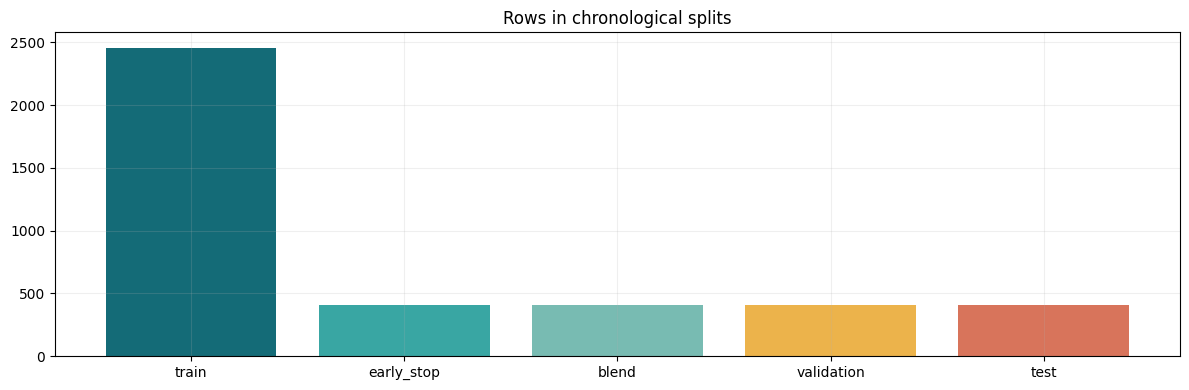

In [8]:
dates = np.array(sorted(dataset.target_date.unique()))
cuts = [0, int(len(dates)*0.6), int(len(dates)*0.7), int(len(dates)*0.8), int(len(dates)*0.9), len(dates)]
split_names = ['train', 'early_stop', 'blend', 'validation', 'test']
splits = {}; split_report = []
for i, name in enumerate(split_names):
    start = cuts[i] + (1 if i else 0)
    chosen_dates = dates[start:cuts[i+1]]
    part = dataset[dataset.target_date.isin(chosen_dates)].reset_index(drop=True)
    assert len(part) > 30 and part.city.nunique() == 3
    splits[name] = part
    part.to_csv(RUN / 'splits' / f'{name}.csv', index=False)
    split_report.append({'split': name, 'rows': len(part), 'input_start': part.input_date.min(),
                         'target_start': part.target_date.min(), 'target_end': part.target_date.max()})
for left, right in zip(split_names, split_names[1:]):
    assert splits[left].target_date.max() < splits[right].input_date.min()
split_report = pd.DataFrame(split_report)
split_report.to_csv(RUN / 'reports' / 'split_ranges.csv', index=False)
display(split_report)
plt.bar(split_report['split'], split_report.rows, color=['#146b77','#39a6a3','#78bbb2','#ecb34b','#d8745b'])
plt.title('Rows in chronological splits'); save_figure('06_split_sizes.png')

## 7. Baseline: AQI ngày mai bằng AQI hôm nay

In [9]:
def metrics(y, pred):
    y = np.asarray(y, dtype=float); pred = np.asarray(pred, dtype=float)
    assert len(y) == len(pred) and np.isfinite(y).all() and np.isfinite(pred).all()
    return {'mae': float(mean_absolute_error(y, pred)), 'rmse': float(np.sqrt(mean_squared_error(y, pred))), 'r2': float(r2_score(y, pred))}
baseline_rows = []
for name in ['validation', 'test']:
    frame = splits[name]
    baseline_rows.append({'split': name, 'model': 'Persistence: AQI tomorrow = today', **metrics(frame.target_aqi, frame.aqi_today)})
baseline_results = pd.DataFrame(baseline_rows)
baseline_results.to_csv(RUN / 'metrics' / 'baseline.csv', index=False)
display(baseline_results)

,split,model,mae,rmse,r2
0,validation,Persistence: AQI tomorrow = today,13.097737,18.792855,0.738201
1,test,Persistence: AQI tomorrow = today,15.279310,20.813382,0.639866


## 8. Train H2O AutoML với đầy đủ nhóm thuật toán
Không giới hạn còn ba thuật toán. Mặc định AutoML cho phép mọi nhóm hỗ trợ hồi quy.
24 mô hình đơn tối đa, 60 giây/mô hình, không đặt giới hạn tổng thời gian làm bỏ qua nhóm phía sau.
Giới hạn này vẫn là ngân sách tính toán, không có nghĩa thử mọi bộ tham số có thể tồn tại.
Nfolds=0 và blending theo thời gian để huấn luyện StackedEnsemble.

In [10]:
import os
h2o.init(max_mem_size='3G', nthreads=2)
assert h2o.estimators.H2OXGBoostEstimator.available(), 'Runtime không hỗ trợ XGBoost; cần runtime Linux Colab.'
hframes = {}
for name, part in splits.items():
    hframes[name] = h2o.H2OFrame(part[predictors + ['target_aqi']])
    hframes[name]['city'] = hframes[name]['city'].asfactor()
aml = H2OAutoML(max_models=24, max_runtime_secs=0, max_runtime_secs_per_model=60,
               nfolds=0, seed=42, sort_metric='RMSE', stopping_metric='RMSE',
               project_name='openmeteo_nextday_' + RUN_ID,
               include_algos=None, exclude_algos=None,
               export_checkpoints_dir=str(RUN / 'models' / 'checkpoints'), verbosity='info')
save_json({'max_models': 24, 'max_runtime_secs_per_model': 60, 'nfolds': 0, 'seed': 42,
           'include_algos': None, 'exclude_algos': None, 'selection': 'validation RMSE',
           'blending': 'chronological dedicated split'}, RUN / 'reports' / 'automl_settings.json')
aml.train(x=predictors, y='target_aqi', training_frame=hframes['train'],
          validation_frame=hframes['early_stop'], blending_frame=hframes['blend'],
          leaderboard_frame=hframes['validation'])
leader = aml.leader
leaderboard = get_leaderboard(aml, extra_columns='ALL').as_data_frame()
leaderboard.to_csv(RUN / 'metrics' / 'leaderboard_validation.csv', index=False)
aml.event_log.as_data_frame().to_csv(RUN / 'logs' / 'automl_events.csv', index=False)
save_json(aml.modeling_steps, RUN / 'reports' / 'executed_modeling_steps.json')
def model_family(model_id):
    return model_id.split('_')[0]
leaderboard['family'] = leaderboard.model_id.map(model_family)
coverage = leaderboard.groupby('family').size().rename('models').reset_index()
coverage.to_csv(RUN / 'reports' / 'algorithm_coverage.csv', index=False)
display(coverage, leaderboard)
required = {'GLM','GBM','DRF','XRT','XGBoost','DeepLearning','StackedEnsemble'}
missing = sorted(required - set(coverage.family))
save_json({'required': sorted(required), 'missing': missing}, RUN / 'reports' / 'algorithm_coverage_check.json')
assert not missing, f'Có nhóm chưa tạo được model: {missing}. Xem automl_events.csv, không coi bản này đã đủ nhóm.'
print('Leader được chọn bằng validation:', leader.model_id)

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: [0.037s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate; [0.037s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate; openjdk version "21.0.12.1" 2026-08-18; OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu); OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
  Starting server from /usr/local/lib/python3.13/dist-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmp4f949v3i
  JVM stdout: /tmp/tmp4f949v3i/h2o_unknownUser_started_from_python.out
  JVM stderr: /tmp/tmp4f949v3i/h2o_unknownUser_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server a

H2O_cluster_uptime:,05 secs
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.8
H2O_cluster_version_age:,11 months and 27 days
H2O_cluster_name:,H2O_from_python_unknownUser_1wke3g
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,2.981 Gb
H2O_cluster_total_cores:,2
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"


Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
AutoML progress: |
16:35:07.287: Project: openmeteo_nextday_20261005_233342_901346
16:35:07.289: Cross-validation disabled by user: no fold column nor nfolds > 1.
16:35:07.291: Setting stopping tolerance adaptively based on the training frame: 0.02017425108896008
16:35:07.291: Build control seed: 42
16:35:07.292: training frame: Frame key: AutoML_1_20261005_163507_training_py_1_sid_bb3b    cols: 22    rows: 2457  chunks: 1    size: 382997  checksum: -8611222366859818630
16:35:07.292: validation frame: Frame key: py_2_si

/usr/local/lib/python3.13/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/usr/local/lib/python3.13/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,family,models
0,DRF,1
1,DeepLearning,5
2,GBM,8
3,GLM,1
4,StackedEnsemble,2
5,XGBoost,8
6,XRT,1


,model_id,rmse,mse,mae,rmsle,mean_residual_deviance,training_time_ms,predict_time_per_row_ms,algo,family
0,StackedEnsemble_AllModels_1_AutoML_1_20261005_...,14.104216,198.928910,10.053161,0.130409,198.928910,1058,0.051536,StackedEnsemble,StackedEnsemble
1,DeepLearning_grid_1_AutoML_1_20261005_163507_m...,14.124847,199.511311,10.612023,0.131523,199.511311,48242,0.039298,DeepLearning,DeepLearning
2,StackedEnsemble_BestOfFamily_1_AutoML_1_202610...,14.244539,202.906897,10.177964,0.131331,202.906897,936,0.197064,StackedEnsemble,StackedEnsemble
3,GBM_grid_1_AutoML_1_20261005_163507_model_2,14.624632,213.879855,10.526248,0.132608,213.879855,1377,0.083631,GBM,GBM
4,DeepLearning_grid_1_AutoML_1_20261005_163507_m...,14.710696,216.404565,10.692013,0.137029,216.404565,26485,0.021752,DeepLearning,DeepLearning
5,GBM_2_AutoML_1_20261005_163507,14.822829,219.716254,10.473634,0.134061,219.716254,1096,0.049286,GBM,GBM
6,GBM_3_AutoML_1_20261005_163507,14.983229,224.497154,10.602776,0.133723,224.497154,1058,0.047877,GBM,GBM
7,GBM_1_AutoML_1_20261005_163507,15.043836,226.317009,10.672078,0.134176,226.317009,6814,0.034173,GBM,GBM
8,XGBoost_3_AutoML_1_20261005_163507,15.188141,230.679618,10.889059,0.137281,230.679618,4036,0.016527,XGBoost,XGBoost
9,DeepLearning_grid_3_AutoML_1_20261005_163507_m...,15.242791,232.342668,10.900102,0.139208,232.342668,27612,0.014866,DeepLearning,DeepLearning


Leader được chọn bằng validation: StackedEnsemble_AllModels_1_AutoML_1_20261005_163507


## 9. So sánh mô hình đơn và kết hợp; chấm Test sau khi đã chọn bằng Validation

In [11]:
family_best = leaderboard.sort_values('rmse').drop_duplicates('family').copy()
family_best[['family','model_id','mae','rmse']].to_csv(RUN / 'metrics' / 'best_per_family_validation.csv', index=False)
test = splits['test']
test_rows = [{'family': 'Baseline', 'model_id': 'Persistence', **metrics(test.target_aqi, test.aqi_today)}]
test_predictions = test[['city','input_date','target_date','target_aqi','aqi_today']].copy()
for row in family_best.itertuples():
    model = h2o.get_model(row.model_id)
    pred = model.predict(hframes['test']).as_data_frame()['predict'].to_numpy()
    test_rows.append({'family': row.family, 'model_id': row.model_id, **metrics(test.target_aqi, pred)})
    if model.model_id == leader.model_id:
        test_predictions['prediction'] = pred
test_comparison = pd.DataFrame(test_rows)
test_comparison.to_csv(RUN / 'metrics' / 'family_comparison_test.csv', index=False)
test_predictions['error'] = test_predictions.prediction - test_predictions.target_aqi
test_predictions.to_csv(RUN / 'predictions' / 'test_predictions.csv', index=False)
leader_metrics = metrics(test.target_aqi, test_predictions.prediction)
save_json({'model_id': leader.model_id, 'test': leader_metrics,
           'baseline_test': metrics(test.target_aqi, test.aqi_today),
           'chosen_on': 'validation RMSE; test does not change leader'}, RUN / 'metrics' / 'leader_test.json')
city_metrics = pd.DataFrame([{'city': city, **metrics(g.target_aqi, g.prediction)} for city, g in test_predictions.groupby('city')])
city_metrics.to_csv(RUN / 'metrics' / 'test_by_city.csv', index=False)
display(family_best[['family','mae','rmse']], test_comparison, city_metrics)
print('Test chỉ chấm điểm; không chọn lại leader theo bảng Test.')

stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%
deeplearning prediction progress: |██████████████████████████████████████████████| (done) 100%


/usr/local/lib/python3.13/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/usr/local/lib/python3.13/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%


/usr/local/lib/python3.13/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/usr/local/lib/python3.13/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


drf prediction progress: |███████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
drf prediction progress: |

...

/usr/local/lib/python3.13/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,family,mae,rmse
0,StackedEnsemble,10.053161,14.104216
1,DeepLearning,10.612023,14.124847
3,GBM,10.526248,14.624632
8,XGBoost,10.889059,15.188141
10,DRF,10.652509,15.366810
11,GLM,11.442638,15.371874
16,XRT,10.913879,15.555094


,family,model_id,mae,rmse,r2
0,Baseline,Persistence,15.279310,20.813382,0.639866
1,StackedEnsemble,StackedEnsemble_AllModels_1_AutoML_1_20261005_...,12.138672,15.801110,0.792435
2,DeepLearning,DeepLearning_grid_1_AutoML_1_20261005_163507_m...,13.235448,16.639726,0.769818
3,GBM,GBM_grid_1_AutoML_1_20261005_163507_model_2,12.995089,16.782399,0.765854
4,XGBoost,XGBoost_3_AutoML_1_20261005_163507,13.534747,17.956239,0.731954
5,DRF,DRF_1_AutoML_1_20261005_163507,12.996149,16.913954,0.762169
6,GLM,GLM_1_AutoML_1_20261005_163507,13.412880,17.160993,0.755170
7,XRT,XRT_1_AutoML_1_20261005_163507,13.380680,17.307358,0.750976


,city,mae,rmse,r2
0,Da Nang,16.182730,20.263430,0.695956
1,Ha Noi,11.973368,14.402274,0.771247
2,TP.HCM,8.259919,11.445225,0.803970


Test chỉ chấm điểm; không chọn lại leader theo bảng Test.


## 10. Biểu đồ kết quả và phân tích lỗi

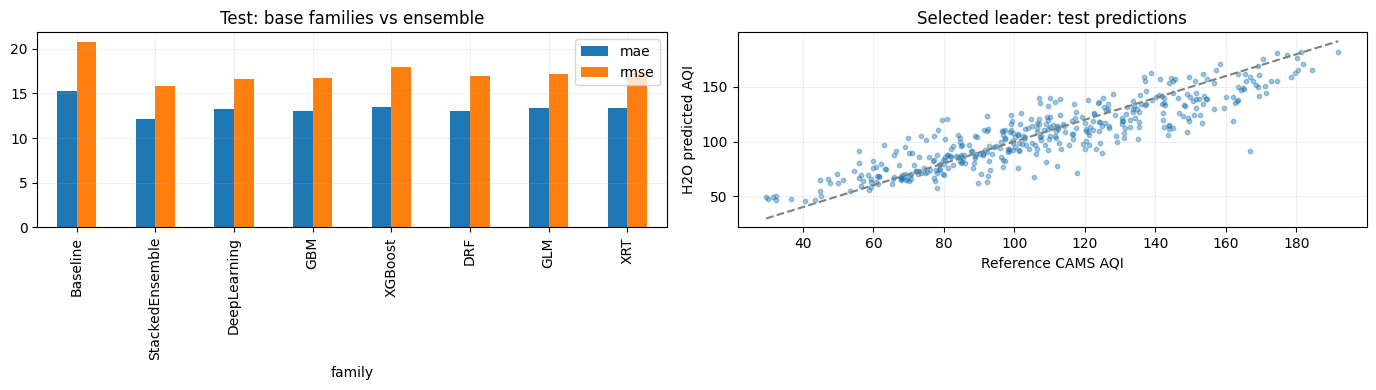

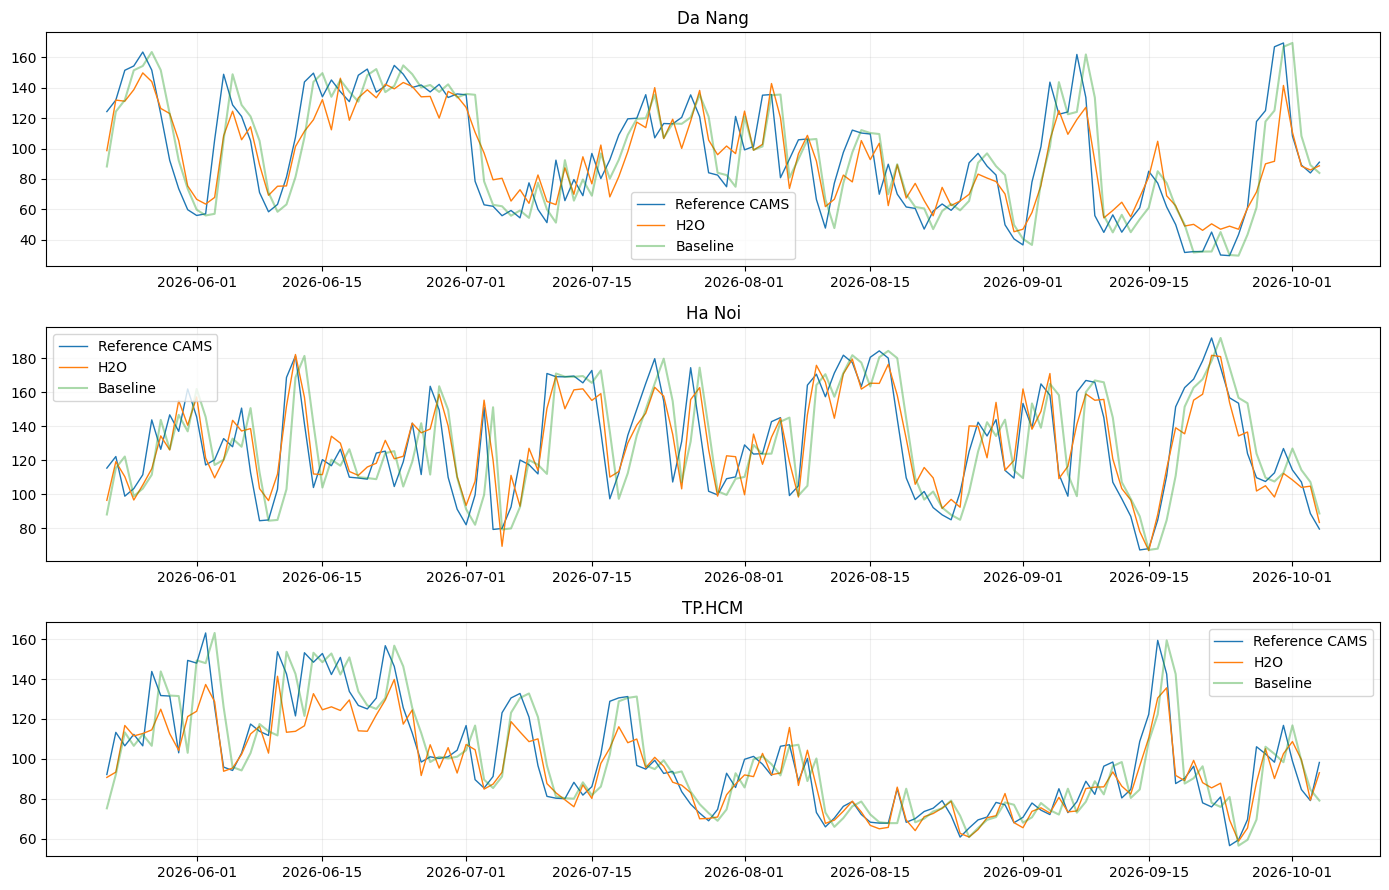

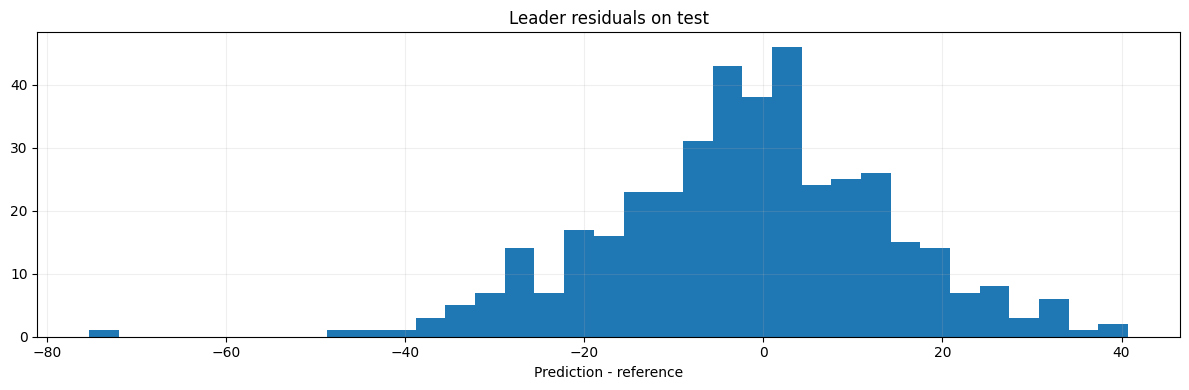

,city,input_date,target_date,target_aqi,aqi_today,prediction,error,abs_error
390,Da Nang,2026-09-28,2026-09-29,166.916667,124.958333,91.624706,-75.291961,75.291961
384,Da Nang,2026-09-26,2026-09-27,117.791667,61.208333,71.439615,-46.352052,46.352052
324,Da Nang,2026-09-06,2026-09-07,161.875000,124.083333,119.094263,-42.780737,42.780737
130,Ha Noi,2026-07-03,2026-07-04,79.375000,151.166667,120.104278,40.729278,40.729278
39,Da Nang,2026-06-03,2026-06-04,148.833333,105.666667,108.362345,-40.470989,40.470989
225,Da Nang,2026-08-04,2026-08-05,80.833333,135.500000,120.285912,39.452578,39.452578
315,Da Nang,2026-09-03,2026-09-04,143.666667,101.166667,105.616264,-38.050403,38.050403
36,Da Nang,2026-06-02,2026-06-03,105.666667,57.083333,67.850180,-37.816487,37.816487
68,TP.HCM,2026-06-12,2026-06-13,153.166667,121.500000,116.546635,-36.620032,36.620032
330,Da Nang,2026-09-08,2026-09-09,55.916667,133.541667,91.563461,35.646795,35.646795


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
test_comparison.plot.bar(x='family', y=['mae','rmse'], ax=axes[0], title='Test: base families vs ensemble')
axes[1].scatter(test_predictions.target_aqi, test_predictions.prediction, s=10, alpha=0.4)
low = min(test_predictions.target_aqi.min(), test_predictions.prediction.min())
high = max(test_predictions.target_aqi.max(), test_predictions.prediction.max())
axes[1].plot([low,high],[low,high], '--', color='grey')
axes[1].set(xlabel='Reference CAMS AQI', ylabel='H2O predicted AQI', title='Selected leader: test predictions')
save_figure('10_test_comparison_scatter.png')
fig, axes = plt.subplots(3, 1, figsize=(14, 9))
for ax, (city, group) in zip(axes, test_predictions.groupby('city')):
    ax.plot(group.target_date, group.target_aqi, label='Reference CAMS', linewidth=1)
    ax.plot(group.target_date, group.prediction, label='H2O', linewidth=1)
    ax.plot(group.target_date, group.aqi_today, label='Baseline', alpha=0.4)
    ax.set_title(city); ax.legend()
save_figure('10_test_timeseries_cities.png')
plt.hist(test_predictions.error, bins=35); plt.title('Leader residuals on test'); plt.xlabel('Prediction - reference')
save_figure('10_test_residuals.png')
worst = test_predictions.assign(abs_error=lambda d: d.error.abs()).nlargest(20, 'abs_error')
worst.to_csv(RUN / 'reports' / 'worst_20_errors.csv', index=False)
display(worst)

## 11. Lưu model và xuất dự đoán ngày kế tiếp từ ngày lịch sử hoàn tất gần nhất

In [13]:
model_dir = RUN / 'models' / 'saved'
model_dir.mkdir(exist_ok=True)
saved_models = []
# Chỉ model thuộc lần AutoML này; kèm metalearner cần cho ensemble.
model_ids = set(leaderboard.model_id)
for model_id in list(model_ids):
    model = h2o.get_model(model_id)
    if model.algo == 'stackedensemble':
        model_ids.add(model.metalearner().model_id)
for model_id in sorted(model_ids):
    model = h2o.get_model(model_id)
    saved_models.append({'model_id': model_id, 'path': h2o.save_model(model, path=str(model_dir), force=True)})
save_json(saved_models, RUN / 'models' / 'saved_models.json')
mojo_path = leader.download_mojo(path=str(RUN / 'models'), get_genmodel_jar=True)
save_json({'leader': leader.model_id, 'mojo': mojo_path, 'h2o_version': h2o.__version__,
           'predictors': predictors, 'target': 'next_day_mean_us_aqi'}, RUN / 'models' / 'leader_manifest.json')
latest = features_all.loc[features_all.input_complete].sort_values('input_date').groupby('city').tail(1).copy()
hf_latest = h2o.H2OFrame(latest[predictors]); hf_latest['city'] = hf_latest['city'].asfactor()
latest['h2o_prediction'] = leader.predict(hf_latest).as_data_frame()['predict'].to_numpy()
next_day = latest[['city','input_date','target_date','h2o_prediction']].copy()
next_day['input_source'] = 'Completed historical CAMS day; not station observation'
next_day.to_csv(RUN / 'predictions' / 'next_day_from_completed_history.csv', index=False)
forecast_hourly = clean_hourly(raw_forecast)
forecast_daily = to_daily(forecast_hourly)
forecast_daily.to_csv(RUN / 'processed' / 'source_forecast_daily_SEPARATE.csv', index=False)
display(next_day, forecast_daily[['city','date','aqi']])
print('H2O dự đoán ngày sau ngày lịch sử cuối cùng. AQI 06/10 trong bảng nguồn dự báo là CAMS, không gọi là dự đoán H2O.')

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%


/usr/local/lib/python3.13/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,city,input_date,target_date,h2o_prediction,input_source
4117,Ha Noi,2026-10-04,2026-10-05,82.401209,Completed historical CAMS day; not station obs...
4116,Da Nang,2026-10-04,2026-10-05,101.894320,Completed historical CAMS day; not station obs...
4118,TP.HCM,2026-10-04,2026-10-05,100.793511,Completed historical CAMS day; not station obs...


,city,date,aqi
0,Da Nang,2026-10-05,69.375000
1,Da Nang,2026-10-06,53.125000
2,Da Nang,2026-10-07,82.666667
3,Da Nang,2026-10-08,59.208333
4,Da Nang,2026-10-09,42.375000
5,Ha Noi,2026-10-05,63.750000
6,Ha Noi,2026-10-06,59.958333
7,Ha Noi,2026-10-07,119.500000
8,Ha Noi,2026-10-08,171.083333
9,Ha Noi,2026-10-09,183.750000


H2O dự đoán ngày sau ngày lịch sử cuối cùng. AQI 06/10 trong bảng nguồn dự báo là CAMS, không gọi là dự đoán H2O.


## 12. Kiểm tra file đầu ra, raw hash và lưu notebook/báo cáo tổng kết

In [23]:
for item in manifest:
    assert hashlib.sha256((raw_dir / item['file']).read_bytes()).hexdigest() == item['sha256'], 'Raw CSV bị thay đổi!'
required_files = ['reports/raw_manifest.json', 'reports/split_ranges.csv', 'reports/algorithm_coverage.csv',
                  'processed/hourly_clean.csv', 'processed/daily_clean.csv', 'features/schema.json',
                  'metrics/leaderboard_validation.csv', 'metrics/family_comparison_test.csv',
                  'predictions/test_predictions.csv', 'models/leader_manifest.json']
assert all((RUN / p).is_file() for p in required_files)
# Snapshot contains exactly 13 current workflow cells, not execution-history attempts.
code_files = sorted((RUN / 'code').glob('*.py'))
workflow_files = []
for step in range(13):
    candidates = [p for p in code_files if p.name.startswith(f'{step:02d}_')]
    assert candidates, f'Missing step {step}'
    workflow_files.append(candidates[0])
for step, marker, prefix in [(2, 'raw_corr_columns =', 'def save_figure'), (4, 'quality_comparison =', 'def to_daily')]:
    candidates = [p for p in code_files if p.read_text(encoding='utf-8').startswith(prefix) and marker in p.read_text(encoding='utf-8')]
    assert candidates, f'Missing updated EDA step {step}'
    workflow_files[step] = max(candidates, key=lambda p: p.stat().st_mtime)
workflow_files[12] = Path(_audit_current['file'])
snapshot_cells = [{'cell_type':'markdown', 'metadata':{}, 'source':['# Open-Meteo H2O: current 13-step code snapshot\n', 'Run cells in order. Raw CSV is read-only. Code folder retains execution history; use this notebook for the current workflow.']}]
for step, file in enumerate(workflow_files):
    source = file.read_text(encoding='utf-8')
    compile(source, str(file), 'exec')
    snapshot_cells.append({'cell_type':'code', 'metadata':{'workflow_step':step}, 'source':source.splitlines(True), 'execution_count':None, 'outputs':[]})
assert len(snapshot_cells) == 14
save_json({'nbformat':4, 'nbformat_minor':5, 'metadata':{'kernelspec':{'name':'python3','display_name':'Python 3'}}, 'cells':snapshot_cells}, RUN / 'notebooks' / 'OpenMeteo_H2O_code_snapshot.ipynb')
save_json([{'step':i, 'source_file':str(p.relative_to(RUN)), 'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for i,p in enumerate(workflow_files)], RUN / 'reports' / 'current_code_manifest.json')

summary = f"""# Open-Meteo H2O — 3 thành phố
Run: {RUN_ID}
Nguồn: CAMS qua Open-Meteo; dữ liệu mô hình, không phải số đo trạm.
Mục tiêu: AQI trung bình ngày kế tiếp; horizon 1 ngày.
Lịch sử: 01/01/2023 đến 04/10/2026. Forecast lưu riêng, không train/test.
Leader chọn trên validation: {leader.model_id}
Test MAE: {leader_metrics['mae']:.4f}; RMSE: {leader_metrics['rmse']:.4f}; R2: {leader_metrics['r2']:.4f}
Các nhóm thực sự đã train: {', '.join(coverage.family)}
So sánh baseline: metrics/baseline.csv. So sánh nhóm: metrics/family_comparison_test.csv.
Raw hash đã kiểm tra lại: nội dung CSV gốc không thay đổi.
Kết quả đo khả năng dự đoán chuỗi CAMS; không chứng minh độ chính xác so với không khí đo thực tế.
Đặc trưng cần ngày đầu vào hoàn tất. Muốn dự đoán 06/10 từ dữ liệu 05/10 phải cập nhật nguồn và xác định giờ chốt.
DeepLearning và giới hạn thời gian từng model có thể làm kết quả thay đổi nhẹ giữa các lần chạy.
"""
(RUN / 'reports' / 'SUMMARY.md').write_text(summary, encoding='utf-8')
save_json({'run_id':RUN_ID, 'path':str(RUN)}, PROJECT / 'LATEST_RUN.json')
eda_required = ['figures/02_before_correlation.png', 'figures/04_before_after_aqi_histogram.png', 'figures/04_before_after_monthly_aqi.png', 'reports/before_correlation.csv', 'reports/after_correlation.csv', 'reports/before_numeric_describe.csv', 'reports/after_numeric_describe.csv', 'reports/quality_before_after.csv']
assert all((RUN / p).is_file() and (RUN / p).stat().st_size > 0 for p in eda_required)
(RUN / 'reports' / 'SUMMARY.md').write_text(summary + '\nEDA update: paired before/after histograms, monthly trend, correlation, full numeric statistics and quality checks. Snapshot has exactly 13 current workflow cells.\n', encoding='utf-8')
audit = {'checked_at':datetime.now(ZoneInfo('Asia/Ho_Chi_Minh')).isoformat(), 'run_id':RUN_ID, 'raw_hash_verified':True, 'snapshot_code_cells':13, 'eda_required':eda_required, 'folders':{}}
for directory in sorted(p for p in RUN.iterdir() if p.is_dir()):
    audit['folders'][directory.name] = [{'file':str(p.relative_to(RUN)), 'bytes':p.stat().st_size} for p in sorted(directory.rglob('*')) if p.is_file()]
save_json(audit, RUN / 'reports' / 'latest_verification.json')
files = pd.DataFrame([{'file':str(p.relative_to(RUN)), 'bytes':p.stat().st_size} for p in RUN.rglob('*') if p.is_file()])
files.to_csv(RUN / 'reports' / 'file_inventory.csv', index=False)
display(files.groupby(files.file.str.split('/').str[0]).agg(files=('file','count'), bytes=('bytes','sum')))
print('HOÀN TẤT. Code, biểu đồ, splits, metrics, models đều đã lưu Drive:', RUN)
print('VERIFIED: RAW HASH OK; CURRENT SNAPSHOT = 13 CELLS; ALL 8 EDA ADDITIONS PRESENT.')


,files,bytes
file,,
code,21,45466
features,2,1448938
figures,13,1790350
logs,2,28771
metrics,6,6417
models,63,79323811
notebooks,1,40190
predictions,2,39673
processed,3,7183558


HOÀN TẤT. Code, biểu đồ, splits, metrics, models đều đã lưu Drive: /content/drive/MyDrive/Bigdata_H20/OpenMeteo_H2O_3_ThanhPho/runs/20261005_233342_901346
VERIFIED: RAW HASH OK; CURRENT SNAPSHOT = 13 CELLS; ALL 8 EDA ADDITIONS PRESENT.
